In [ ]:
# now since MLA performed almost the same as GQA but was trained on more tokens (400m), for this run, I'd revert back to GQA
# After reading a few research papers, some changes that I'd like to implement for this run are (citations in the block below):

# 1) MobileLLM Architecture (deep over shallow)
# 2) Differential attention
# 3) Parallel Attention and Feed-Forward Net Design for Pre-training and Inference on Transformers
# 4) cross-layer attention sharing and cross-layer kv sharing
# 5) MBR/ best of n
# 6) beam or contrastive search
# let's see how many of these can I implement
''' Parameters: around 120M
FFN: SwiGLU
Norm: RMSNorm
Positional embeddings: RoPE
Context: around 1200
Precision: FP16
Attention: GQA, PyTorch SDPA
Training tokens: 400M
'''


In [ ]:
'''finally, this is what I'm applying:
1) Parallel attention (Parallel Attention and Feed-Forward Net Design for Pre-training and Inference on Transformers by  
Shashank Sonkar, et al.) + MLP block
2) Differential attention (two softmax maps, subtract with learned λ)	Attention change.
finally I didn't add it bcs of limited compute and limited returns
3) mobile llm'''

# Architecture of this submission:

1) Almost similar to last submission, except that it uses MLA implementation this time, lower parameter count and higher training tokens.

2) Positions use AliBi
3) The MLP is SwiGLU
Normalization is RMSNorm (eps 1e-5, computed in fp32) before attention, before the MLP, and once at the end.
4) Vocab is 33,000, and the input and output embeddings are tied.
5) There is no dropout, no QK-norm, and no attention masking across document boundaries.
Init is N(0, 0.02) everywhere. The attention-out and MLP-down projections use 0.02/√(2·14) ≈ 0.0038.
The loss is plain next-token cross-entropy on fp32 logits, with no label smoothing.

**Citations:**

# Possible questions: 
1) what is label smoothing? 

In [ ]:
# some important notes: 

# Mixed precision training

This represents Mixed Precision Training, a technique used to speed up training and save GPU memory:
• fp16 autocast: The model automatically runs forward and backward passes using 16-bit floating-point numbers (fp16) instead of standard 32-bit (fp32). This drastically speeds up matrix multiplications on modern GPUs.
• fp32 master weights: Because 16-bit numbers are less precise, a backup copy of the model's weights is kept in full 32-bit precision. The optimizer applies updates to these fp32 master weights, which are then copied back down to fp16 for the next step.
• GradScaler: Small gradients can "underflow" (become zero) in 16-bit space. The GradScaler multiplies the loss by a large factor before backpropagation to scale up the gradients, then shrinks them back down before the optimizer updates the weights.

Hate Speech Detection
Using the ETHOS dataset provided in Mollas et al.
(2020) and instrumented by Chiu and Alexander
(2021), we measure the ability of OPT-175B to
identify whether or not certain English statements
are racist or sexist (or neither). I'll try to implement it in the final submission.
OPT: Open Pre-trained Transformer Language Models
Susan Zhang et al

# Choice of LR schedule:
1) It is standard for llms to use a cosine scheduled sampling, hence I did it too. 
2) Something I'd like to implement now, after reading this paper is infinite lr
   citation: BEYOND COSINE DECAY: ON THE EFFECTIVENESS OF INFINITE
LEARNING RATE SCHEDULE FOR CONTINUAL PRE-TRAINING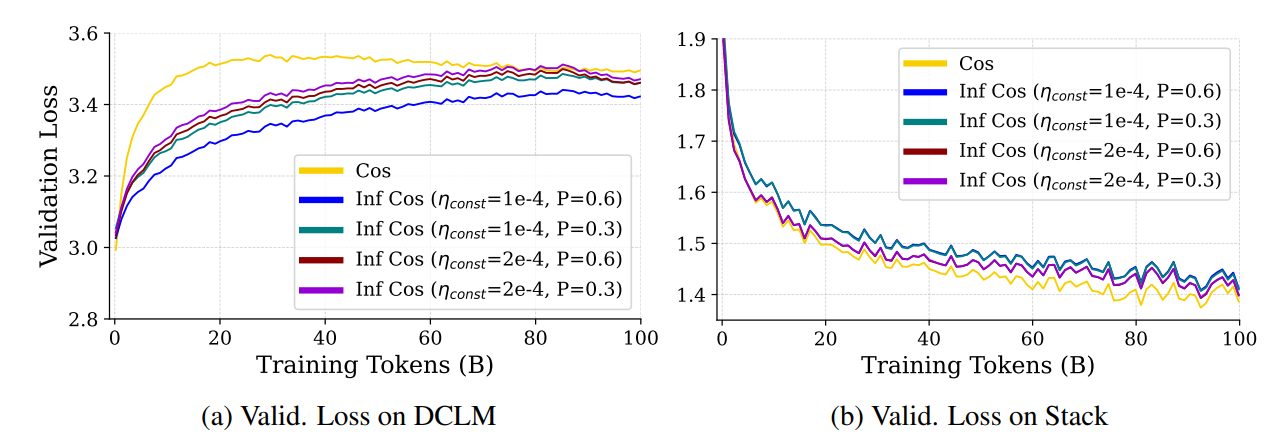

# Deepseek MoE

Something I liked reading about was how deepseek advanced the standard MoE 
    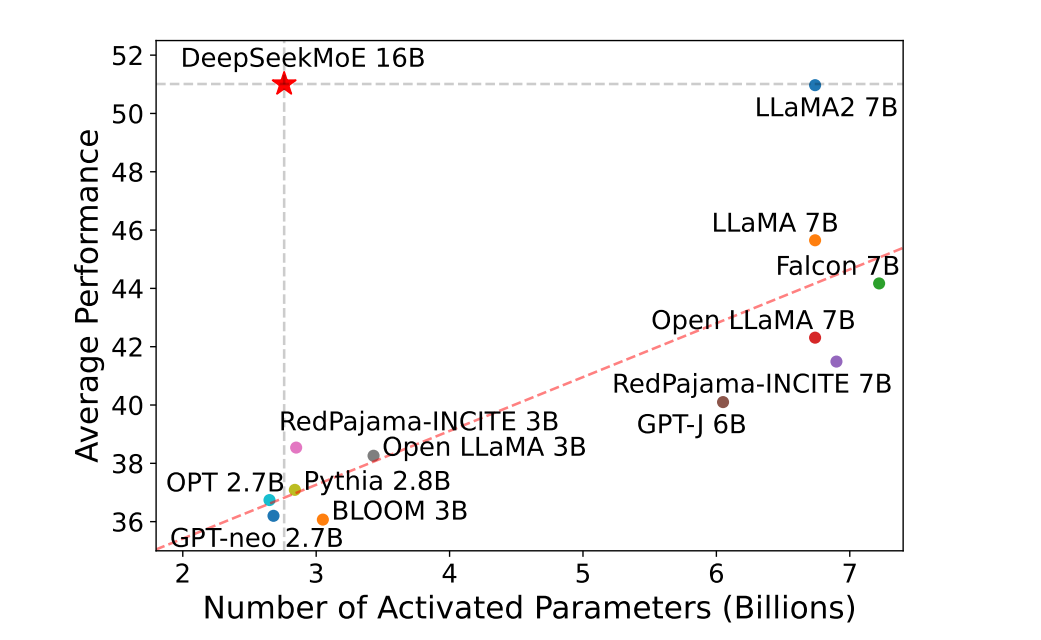

# Chinchilla scaling laws

I understand now that my model is severely undertrained, so I'll reduce the parameter count and increase training tokens

Citations: 
1) DeepSeekMoE: Towards Ultimate Expert Specialization in Mixture-of-Experts Language Models
2) Training Compute-Optimal Large Language Models

# MLA architecture

solves the memory bottleneck of KV cache in LLMs without sacrificing model performance
doesn't work with rope hence uses decoupled rope

# MobileLLM architecture

MobileLLM architecture is used for running llms directly on resource constrained devices like smartphones with sub-billion parameter models.
To do this, they use: 
1) Deep and Thin Layouts
2) Embedding Sharing
3) GQA
4) Block-Wise Weight Sharing

Citations: 
1) MobileLLM: Optimizing Sub-billion Parameter Language Models for On-Device Use Cases Liu et al.



# This model changes:


# Cleaning: 

1) "\\_\\_":
2) .\
3) " ...": 1611
4) ................................
5) ".â": 2319,
6) "\\_\\_\\_\\_": 2397,

In [ ]:
'''stuff I wanted to try for the previous submission (s3): 
    1) the model should perform better on supreme court data, so increasing its training token count
    2) train on some general open source data like from wikipedia
    3) clean the data better this time
    4) increase temperature and pmax
    5) I wanna implement MLA this time. Paper: DeepSeek-V2: A Strong, Economical, and Efficient
Mixture-of-Experts Language Model
    '''

'''stuff that I tried:
    1) performing better on supreme court data by increasing tokens, worked but not by much
    2) didn't use FineWeb, FineWiki etc. Not gonna use em for this run either
    3) did clean and dedup better
    4) remained same
    5) did implement mla
'''

In [ ]:
!pip install ijson
import os
import sys
import json
import math
import time
import random
import zipfile
from typing import List, Tuple, Dict, Any, Generator
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from tqdm.auto import tqdm
import numpy as np, ijson
from multiprocessing import Pool

In [ ]:

HF_TOKEN = None
if "HF_TOKEN" in os.environ:
    HF_TOKEN = os.environ["HF_TOKEN"]
else:
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        HF_TOKEN = user_secrets.get_secret("HF")
        os.environ["HF_TOKEN"] = HF_TOKEN
        print("Successfully loaded HF_TOKEN from Kaggle Secrets.")
    except Exception as e:
        print(f"Note: Kaggle secrets not detected or HF key missing ({e}). Will attempt public access.")

if HF_TOKEN:
    try:
        from huggingface_hub import login
        login(token=HF_TOKEN)
        print("Huggingface hub authentication successful.")
    except Exception as err:
        print(f"HF Login warning: {err}")


print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device Count: {torch.cuda.device_count()}")
    for i in range(torch.cuda.device_count()):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
        
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
from huggingface_hub import HfApi

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"


# Destination HF repo for uploading your trained tokenizer (e.g. "your-username/legal-bpe-tokenizer")
# Set your HF username or desired repo ID below:
HF_TOKENIZER_UPLOAD_REPO = os.environ.get("HF_TOKENIZER_UPLOAD_REPO", "legal-bpe-tokenizer-phase1")


TRAIN_FILES = ["Phase_1_Pretraining/Train/train_supreme_court.json", "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json", "Phase_1_Pretraining/Train/train_tribunals.json"]

TEST_FILES = ["Phase_1_Pretraining/Test/Phase1- Test.json", "Phase_1_Pretraining/Test/test.json"]

TOKEN_BUDGETS = {"train_supreme_court.json": 112_000_000, "train_acts.json": 112_000_000,
    "train_high_courts.json": 63_000_000, "train_tribunals.json": 63_000_000,}


# TRAIN_TOKENS = 200_000_000
# VAL_TOKENS = 5_000_000

# print("Training token budget:", TRAIN_TOKENS)
# print("Validation token budget:", VAL_TOKENS)


TRAIN_BLOCK_SIZE = 2048
MODEL_CONTEXT_LENGTH = 2048

VOCAB_SIZE = 33000
SEED = 67
random.seed(SEED)
torch.manual_seed(SEED)

BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 4
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1
EPOCHS = 1
TARGET_WORDS = 128
MAX_NEW_TOKENS = 256
TEMPERATURE = 0.1
TOP_P = 0.95
TOP_K = 30
REPETITION_PENALTY = 1.2


KNOWN_COUNTS = {"train_supreme_court.json": 55549, "train_acts.json": 18826,
                "train_high_courts.json": 2536738, "train_tribunals.json": 869132}

CTX = 2048
HF_TOK_REPO = f"{HfApi(token=HF_TOKEN).whoami()['name']}/legal-bpe-tokenizer-phase1-v2"

OUTPUT_DIR = "/kaggle/working/cs781_phase1" if os.path.exists("/kaggle") else "./outputs"
TOKENIZER_DIR = os.path.join(OUTPUT_DIR, "custom_bpe_tokenizer_v2")
TOKEN_DATA_DIR = os.path.join(OUTPUT_DIR, "token_data_v3")

CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "model_checkpoint")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TOKENIZER_DIR, exist_ok=True)
os.makedirs(TOKEN_DATA_DIR, exist_ok=True)


TRAIN_BIN = os.path.join(TOKEN_DATA_DIR, "train.bin")
VAL_BIN   = os.path.join(TOKEN_DATA_DIR, "val.bin")


N_HEAD = 8


print("\nConfiguration loaded")
print(f"Target Token Splits: {TOKEN_BUDGETS}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Tokenizer repository: {HF_TOK_REPO}")
print(f"Vocabulary size: {VOCAB_SIZE}")
print(f"Context length: 1256")

In [ ]:

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
from transformers import PreTrainedTokenizerFast
from huggingface_hub import hf_hub_download

def download_data():
    local_train_paths = []
    print("\nDownloading phase 1 training data.")
    for tf in TRAIN_FILES:
        try:
            p = hf_hub_download(repo_id = HF_DATASET_REPO, filename = tf, repo_type = "dataset", token = HF_TOKEN)
            local_train_paths.append(p)
            print(f"Downloaded: {tf}")
        except Exception as e:
            print(f"Warning downloading {tf}: {e}")
            
    test_path = None
    for tf in TEST_FILES:
        try:
            test_path = hf_hub_download(repo_id = HF_DATASET_REPO, filename = tf, repo_type = "dataset", token = HF_TOKEN)
            print(f"Downloaded Test File: {tf}")
            break
        except Exception:
            continue
            
    return local_train_paths, test_path

In [ ]:
train_paths, test_path = download_data()

# inspect_json_files(train_paths, n=250)

In [ ]:
# making a cleaning function anf removing stuff from the junk patterns I saw and noted earlier
import re

_CTRL    = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f\u200b-\u200d\u2060\ufeff]")
_MOJI    = re.compile(r"[\u00c2\u00c3\u00e2][\u0080-\u00bf\u0152\u0153\u0160\u0161\u0178\u017d\u017e\u0192\u02c6\u02dc"
                      r"\u2013\u2014\u2018-\u201e\u2020-\u2022\u2026\u2030\u2039\u203a\u20ac\u2122]{1,3}")
_STRAY   = re.compile(r"[\u00c2\u00e2](?=\s|$)")                       # leftover  Â  /  â  before a space
_LITESC  = re.compile(r"\\([nrt])")                                    # literal backslash-n / -r / -t
_ESC     = re.compile(r"\\([\\`*_{}\[\]()#+\-.!|<>~=:;,'\"&%$@^/?])")  # markdown escapes  \_  \.  \-
_HSPACE  = re.compile(r"[ \t\u00a0\u1680\u2000-\u200a\u202f\u205f\u3000]+")
_UNDER   = re.compile(r"_{2,}")                                        # __ ____  (what \_\_ \_\_\_\_ becomes)
_RUNS    = re.compile(r"(?:[_\-=*~#+|] ?){3,}")                        # -----  =====  *****  _ _ _ _  ###
_DOTS_AT = re.compile(r"(?<=[^\W_])(?:[.\u2026]{3,}|\u2026)")          # so....  so…   (attached to a word)
_DOTS    = re.compile(r"(?: ?[.\u2026]){3,}|[ ]?\u2026")               # " ..."  "........"  ". . ."  "…"
_DEVA    = re.compile(r"[\u0900-\u097f]")

def _fix_moji(m):
    s = m.group(0)
    try:
        return bytes(ord(c) if ord(c) < 256 else c.encode("cp1252")[0] for c in s).decode("utf-8")
    except (UnicodeError, ValueError):
        return " "                                                     # unrepairable junk -> drop it

def clean_text(t):
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = _CTRL.sub("", t)
    if "\u00c2" in t or "\u00c3" in t or "\u00e2" in t:               # mojibake:  â€™  â€¦  Â\xa0  Ã©
        t = _MOJI.sub(_fix_moji, t)
        t = _STRAY.sub("", t)
    t = _LITESC.sub(lambda m: "\n" if m.group(1) == "n" else " ", t)
    t = _ESC.sub(r"\1", t)
    t = t.replace("\\", " ")                                           # any backslash left (".\" etc.)
    t = _HSPACE.sub(" ", t)                                            # collapse first: keeps the regexes linear
    t = _UNDER.sub(" ", t)
    t = _RUNS.sub(" ", t)
    t = _DOTS_AT.sub(". ", t)                                          # "so...." -> "so." (keeps the sentence end)
    t = _DOTS.sub(" ", t)
    t = _HSPACE.sub(" ", t)
    t = re.sub(r" ?\n ?", "\n", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def keep_doc(t, min_words=100):
    if len(t.split(None, min_words)) <= min_words: return False       # too short to be useful
    s = t[:20000]
    return len(_DEVA.findall(s)) <= 0.02 * len(s)                       # mostly-Devanagari docs waste tokens

In [ ]:
# checking if it's working

import ijson
PAT = {"escaped underscore \\_": r"\\_", "any backslash": r"\\", "3+ dots": r"\.{3,}", "spaced ' ...'": r" \.\.\.",
       "unicode …": "\u2026", "mojibake â Â Ã": "[\u00e2\u00c2\u00c3]", "2+ spaces": r" {2,}",
       "underscore run": r"_{2,}", "dash/eq/star run": r"[-=*~#]{3,}"}
for p in train_paths:
    with open(p, "rb") as f:
        docs = [r["text"] for _, r in zip(range(300), ijson.items(f, "item")) if r.get("text")]
    cl = [clean_text(d) for d in docs]
    print(f"{os.path.basename(p)} | kept {sum(keep_doc(c) for c in cl)}/{len(cl)} docs | chars {sum(map(len, docs)):,} -> {sum(map(len, cl)):,}")
    for k, pat in PAT.items():
        b = sum(len(re.findall(pat, d)) for d in docs); a = sum(len(re.findall(pat, d)) for d in cl)
        if b: print(f"   {k:24s} {b:8d} -> {a}")

In [ ]:
# !rm -f {TOKEN_DATA_DIR}/*.bin

In [ ]:
'''import ijson
import os

def count_entries(file_paths):

    for path in file_paths:

        print("=" * 100)
        print("FILE:", path)

        count = 0

        with open(path, "rb") as f:
            entries = ijson.items(f, "item")

            for _ in entries:
                count += 1

        print("Total entries:", count)

count_entries(train_paths)'''


'''
====================================================================================================
FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json
Total entries: 55549
====================================================================================================
FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_acts.json
Total entries: 18826
====================================================================================================
FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_high_courts.json
Total entries: 2536738
====================================================================================================
FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_tribunals.json
Total entries: 869132
'''

The output to the above cell is: 

FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json
Total entries: 55549

FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_acts.json
Total entries: 18826

FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_high_courts.json
Total entries: 2536738

FILE: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_tribunals.json
Total entries: 869132

In [ ]:
import regex


_PAT = regex.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")


class PureByteLevelBPETokenizer:
    def __init__(self, vocab_size: int = 33000):
        self.vocab_size = vocab_size
        self.special_tokens = ["<pad>", "<unk>", "<s>", "</s>", "<mask>"]

        self.encoder: Dict[bytes, int] = {}
        self.decoder: Dict[int, bytes] = {}
        self.merges: Dict[Tuple[bytes, bytes], bytes] = {}       # pair -> merged token
        self.merge_ranks: Dict[Tuple[bytes, bytes], int] = {}    # pair -> order learned (lower = earlier)
        self._cache: Dict[str, List[int]] = {}

        self._init_base_vocab()

    def _init_base_vocab(self):
        for b in range(256):
            b_bytes = bytes([b])
            self.encoder[b_bytes] = b
            self.decoder[b] = b_bytes

        # special tokens
        for idx, token in enumerate(self.special_tokens, start=256):
            b_bytes = token.encode("utf-8")
            self.encoder[b_bytes] = idx
            self.decoder[idx] = b_bytes

    @property
    def pad_token_id(self) -> int:
        return self.encoder["<pad>".encode("utf-8")]

    @property
    def unk_token_id(self) -> int:
        return self.encoder["<unk>".encode("utf-8")]

    @property
    def bos_token_id(self) -> int:
        return self.encoder["<s>".encode("utf-8")]

    @property
    def eos_token_id(self) -> int:
        return self.encoder["</s>".encode("utf-8")]

    # ------------------------------------------------------------------ training
    @staticmethod
    def _merge_word(word, a, b, new):
        out, i, n = [], 0, len(word)
        while i < n:
            if i < n - 1 and word[i] == a and word[i + 1] == b:
                out.append(new)
                i += 2
            else:
                out.append(word[i])
                i += 1
        return out

    def train_from_texts(self, texts: List[str], target_vocab_size: int = None, min_word_freq: int = 2):
        if target_vocab_size is None:
            target_vocab_size = self.vocab_size
        num_merges = target_vocab_size - len(self.encoder)
        print(f"\nTraining byte level BPE from scratch. Target merges: {num_merges:,} | Base Vocab: {len(self.encoder)}")

        # 1) pre-tokenize + count unique words (the BPE then runs on this small table, not the raw text)
        word_counts = Counter()
        for text in tqdm(texts, desc="Counting pre-tokens"):
            if text and text.strip():
                word_counts.update(_PAT.findall(text))

        words, freqs = [], []
        for w, c in word_counts.items():
            if c >= min_word_freq:
                words.append([bytes([b]) for b in w.encode("utf-8", "replace")])
                freqs.append(c)
        del word_counts
        print(f"Unique words used for merge learning: {len(words):,}")

        # 2) initial pair statistics (updated incrementally afterwards)
        pair_counts = defaultdict(int)
        where = defaultdict(set)
        for i, w in enumerate(tqdm(words, desc="Initial pair counts")):
            for p in zip(w, w[1:]):
                pair_counts[p] += freqs[i]
                where[p].add(i)

        # 3) merge loop
        pbar = tqdm(total=num_merges, desc="Learning BPE Merges", dynamic_ncols=True)
        for _ in range(num_merges):
            if not pair_counts:
                print("No more candidate pairs found to merge.")
                break

            best_pair, freq = max(pair_counts.items(), key=lambda kv: kv[1])
            if freq < 2:
                print(f"Stopping early: Most frequent pair frequency is {freq}")
                break

            a, b = best_pair
            merged_token = a + b
            self.merges[best_pair] = merged_token
            self.merge_ranks[best_pair] = len(self.merge_ranks)
            if merged_token not in self.encoder:          # two merge paths can give the same bytes
                new_id = len(self.encoder)
                self.encoder[merged_token] = new_id
                self.decoder[new_id] = merged_token

            for i in list(where[best_pair]):
                w, f = words[i], freqs[i]
                for p in zip(w, w[1:]):
                    pair_counts[p] -= f
                    if pair_counts[p] <= 0:
                        del pair_counts[p]
                w = self._merge_word(w, a, b, merged_token)
                words[i] = w
                for p in zip(w, w[1:]):
                    pair_counts[p] += f
                    where[p].add(i)
            del where[best_pair]
            pair_counts.pop(best_pair, None)

            pbar.update(1)
            pbar.set_postfix({"vocab_size": len(self.encoder), "top_pair_freq": freq})

        pbar.close()
        self._cache.clear()
        print(f"Training finished! Final Vocab Size: {len(self.encoder):,}")

    # ------------------------------------------------------------------ encode / decode
    def _encode_word(self, word: str) -> List[int]:
        cached = self._cache.get(word)
        if cached is not None:
            return cached
        tokens = [bytes([b]) for b in word.encode("utf-8", "replace")]
        while len(tokens) >= 2:
            best_pair, best_rank = None, None
            for p in zip(tokens, tokens[1:]):
                r = self.merge_ranks.get(p)
                if r is not None and (best_rank is None or r < best_rank):
                    best_pair, best_rank = p, r
            if best_pair is None:
                break
            tokens = self._merge_word(tokens, best_pair[0], best_pair[1], self.merges[best_pair])
        ids = [self.encoder.get(t, self.unk_token_id) for t in tokens]
        if len(self._cache) < 1_000_000:
            self._cache[word] = ids
        return ids

    def encode(self, text: str) -> List[int]:
        ids: List[int] = []
        for word in _PAT.findall(text):
            ids.extend(self._encode_word(word))
        return ids

    def decode(self, token_ids: List[int]) -> str:
        raw_bytes = b"".join(self.decoder.get(i, b"<unk>") for i in token_ids)
        return raw_bytes.decode("utf-8", errors="replace")

    # ------------------------------------------------------------------ save / load
    def save(self, save_dir: str):
        os.makedirs(save_dir, exist_ok=True)
        vocab_path = os.path.join(save_dir, "vocab.json")
        merges_path = os.path.join(save_dir, "merges.json")
        config_path = os.path.join(save_dir, "tokenizer_config.json")

        # latin1 maps bytes 1:1 onto code points, so any byte string survives JSON
        ser_vocab = {k.decode("latin1"): v for k, v in self.encoder.items()}
        with open(vocab_path, "w", encoding="utf-8") as f:
            json.dump(ser_vocab, f, ensure_ascii=False, indent=2)

        # JSON (not a space-separated text file): tokens can contain spaces, newlines, \r, \xa0 ...
        ser_merges = [[p1.decode("latin1"), p2.decode("latin1")] for (p1, p2) in self.merges]  # in learned order
        with open(merges_path, "w", encoding="utf-8") as f:
            json.dump(ser_merges, f, ensure_ascii=False)

        config = {
            "tokenizer_class": "PureByteLevelBPETokenizer",
            "vocab_size": len(self.encoder),
            "special_tokens": self.special_tokens,
            "pad_token_id": self.pad_token_id,
            "bos_token_id": self.bos_token_id,
            "eos_token_id": self.eos_token_id
        }
        with open(config_path, "w", encoding="utf-8") as f:
            json.dump(config, f, indent=2)

        print(f"Tokenizer saved successfully to {save_dir}")

    @classmethod
    def load(cls, save_dir: str) -> "PureByteLevelBPETokenizer":
        tok = cls()
        with open(os.path.join(save_dir, "vocab.json"), "r", encoding="utf-8") as f:
            ser_vocab = json.load(f)
        tok.encoder = {k.encode("latin1"): v for k, v in ser_vocab.items()}
        tok.decoder = {v: k.encode("latin1") for k, v in ser_vocab.items()}

        tok.merges, tok.merge_ranks = {}, {}
        with open(os.path.join(save_dir, "merges.json"), "r", encoding="utf-8") as f:
            for rank, (s1, s2) in enumerate(json.load(f)):
                p1, p2 = s1.encode("latin1"), s2.encode("latin1")
                tok.merges[(p1, p2)] = p1 + p2
                tok.merge_ranks[(p1, p2)] = rank
        return tok


In [ ]:
# Upload Trained Tokenizer onto Hugging Face Hub
from huggingface_hub import HfApi, create_repo

def upload_tokenizer_to_hf(tokenizer_dir: str, repo_id: str):
    if not HF_TOKEN:
        print("No HF_TOKEN found, skipping upload.")
        return
    print(f"\nPreparing to upload tokenizer files to Hugging Face Hub repo: '{repo_id}'...")
    api = HfApi(token=HF_TOKEN)

    try:
        # create_repo returns the fully qualified "username/name" id; a bare name would fail in upload_file
        repo_id = create_repo(repo_id=repo_id, token=HF_TOKEN, exist_ok=True, repo_type="model").repo_id
        print(f"  Hugging Face repository '{repo_id}' is ready.")

        files_to_upload = [f for f in os.listdir(tokenizer_dir) if os.path.isfile(os.path.join(tokenizer_dir, f))]
        for file_name in tqdm(files_to_upload, desc="Uploading files to HF"):
            api.upload_file(path_or_fileobj=os.path.join(tokenizer_dir, file_name),
                            path_in_repo=file_name, repo_id=repo_id, repo_type="model")

        print(f"\nSUCCESS: Tokenizer uploaded to https://huggingface.co/{repo_id}")
    except Exception as err:
        print(f"Notice during HF Upload: {err}")
        print("To upload to your own HF account, set HF_TOKENIZER_UPLOAD_REPO = 'your_username/your_repo_name'.")

# upload_tokenizer_to_hf(TOKENIZER_DIR, HF_TOKENIZER_UPLOAD_REPO)

In [ ]:
from tqdm.auto import tqdm
import os
from typing import List
import ijson

CHARS_PER_FILE = 20_000_000

def extract_training_sample(file_paths: List[str], chars_per_file: int = CHARS_PER_FILE) -> List[str]:
    sampled_texts = []
    print(f"\nExtracting ~{chars_per_file:,} chars from each file for tokenizer merge learning...")

    for path in file_paths:
        fname = os.path.basename(path)
        seen = 0
        try:
            with open(path, "rb") as f, tqdm(total=chars_per_file, unit="char", unit_scale=True, desc=fname) as pbar:
                for rec in ijson.items(f, "item"):
                    if not isinstance(rec, dict):
                        continue
                    text = clean_text((rec.get("text") or "").strip())
                    if text and keep_doc(text, 100):
                        sampled_texts.append(text)
                        seen += len(text)
                        pbar.update(len(text))
                    if seen >= chars_per_file:
                        break
        except Exception as err:
            print(f"Error reading {fname}: {err}")
        if seen < chars_per_file:
            print(f"  WARNING: {fname} only gave {seen:,} chars")

    print(f"Extracted {len(sampled_texts):,} documents for tokenizer training.")
    return sampled_texts

# training_corpus = extract_training_sample(train_paths)

In [ ]:
# Train Pure Byte-Level BPE Tokenizer from Scratch

from huggingface_hub import HfApi, hf_hub_download
TOK_FILES = ["vocab.json", "merges.json", "tokenizer_config.json"]
# HF_TOK_REPO = f"{HfApi(token=HF_TOKEN).whoami()['name']}/legal-bpe-tokenizer-phase1"

def get_tokenizer():
    if all(os.path.exists(os.path.join(TOKENIZER_DIR, f)) for f in TOK_FILES):
        print("Loaded tokenizer from disk");  return PureByteLevelBPETokenizer.load(TOKENIZER_DIR)
    try:
        for f in TOK_FILES:
            hf_hub_download(HF_TOK_REPO, f, repo_type="model", local_dir=TOKENIZER_DIR, token=HF_TOKEN)
        print("Loaded tokenizer from HF"); return PureByteLevelBPETokenizer.load(TOKENIZER_DIR)
    except Exception as e:
        print("No saved tokenizer found:", e); return None

tokenizer = get_tokenizer()
if tokenizer is None: # only runs the very first time
    training_corpus = extract_training_sample(train_paths)
    tokenizer = PureByteLevelBPETokenizer(VOCAB_SIZE)
    tokenizer.train_from_texts(training_corpus, target_vocab_size=VOCAB_SIZE)
    tokenizer.save(TOKENIZER_DIR)
    upload_tokenizer_to_hf(TOKENIZER_DIR, HF_TOK_REPO)

No saved tokenizer found: 404 Client Error. (Request ID: Root=1-6ac12a50-5541db2b1b7ba8a03e3dd539;4ed67c81-41bb-4701-9716-7a1733b46a5c)

Repository Not Found for url: https://huggingface.co/DumbLad/legal-bpe-tokenizer-phase1-v2/resolve/main/vocab.json.
Please make sure you specified the correct `repo_id` and `repo_type`.
If you are trying to access a private or gated repo, make sure you are authenticated and your token has the required permissions.
For more details, see https://huggingface.co/docs/huggingface_hub/authentication

Extracting ~20,000,000 chars from each file for tokenizer merge learning...
Loading widget...
Loading widget...
Loading widget...
Loading widget...
Extracted 8,456 documents for tokenizer training.

Training byte level BPE from scratch. Target merges: 32,739 | Base Vocab: 261
Loading widget...
Unique words used for merge learning: 66,944
Loading widget...
Loading widget...
Training finished! Final Vocab Size: 33,000
Tokenizer saved successfully to /kaggle/working/cs781_phase1/custom_bpe_tokenizer_v2

Preparing to upload tokenizer files to Hugging Face Hub repo: 'DumbLad/legal-bpe-tokenizer-phase1-v2'...
  Hugging Face repository 'DumbLad/legal-bpe-tokenizer-phase1-v2' is ready.
Loading widget...

SUCCESS: Tokenizer uploaded to https://huggingface.co/DumbLad/legal-bpe-tokenizer-phase1-v2

In [ ]:
# Rigorous Tokenizer Sanity Checks
print("\n================ SANITY CHECK REPORT ================")

# 1. Roundtrip Fidelity Test
test_sentence = "The Madras Temple Entry Authorization Act, 1947: PETITIONER vs RESPONDENT in Civil Appeal No. 84 of 1959."
encoded_ids = tokenizer.encode(test_sentence)
decoded_sentence = tokenizer.decode(encoded_ids)

print(f"[Check 1] Original String : '{test_sentence}'")
print(f"[Check 1] Token Count     : {len(encoded_ids)} tokens")
print(f"[Check 1] Decoded String  : '{decoded_sentence}'")
assert test_sentence == decoded_sentence, "ERROR: Roundtrip decode did not match original string!"
print("  -> PASS: 100% Exact Roundtrip Match!")

# 2. Special Tokens Validation
print(f"[Check 2] Special Tokens  : BOS={tokenizer.bos_token_id}, EOS={tokenizer.eos_token_id}, PAD={tokenizer.pad_token_id}, UNK={tokenizer.unk_token_id}")
assert len(set([tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id, tokenizer.unk_token_id])) == 4, "ERROR: Duplicate Special Token IDs!"
print("  -> PASS: All Special Tokens Unique & Bound!")

# 3. Save & Load Reload Check
reloaded_tokenizer = PureByteLevelBPETokenizer.load(TOKENIZER_DIR)
reloaded_encoded = reloaded_tokenizer.encode(test_sentence)
assert encoded_ids == reloaded_encoded, "ERROR: Reloaded tokenizer encoding mismatch!"
print("  -> PASS: Save/Load State Integrity Verified!")

# 3b. Reload check on awkward characters (spaces, newlines, non-ASCII all appear inside tokens)
hard = "Held:  that\n\nSection 12 \u00a7 3\r\n\u0939\u093f\u0902\u0926\u0942 appellant."
assert reloaded_tokenizer.decode(reloaded_tokenizer.encode(hard)) == hard, "ERROR: hard-string roundtrip failed"
assert len(reloaded_tokenizer.merges) == len(tokenizer.merges), "ERROR: merges lost on reload"
print("  -> PASS: Hard-string roundtrip + all merges reloaded!")

# 4. Compression Ratio Analysis
sample_bytes = len(test_sentence.encode('utf-8'))
compression = sample_bytes / len(encoded_ids)
print(f"[Check 4] Compression     : {sample_bytes} bytes -> {len(encoded_ids)} tokens ({compression:.2f} bytes/token)")
print("====================================================\n")

In [ ]:
def iter_sampled(path, n_docs, seed=42, val_frac=0.01, max_scan=None):
    total = min(KNOWN_COUNTS[os.path.basename(path)], max_scan or 10**12)
    rng = random.Random(seed)
    chosen = set(rng.sample(range(total), min(n_docs, total)))
    last = max(chosen)
    with open(path, "rb") as f:
        for i, rec in enumerate(ijson.items(f, "item")):
            if i > last: break
            if i in chosen:
                t = (rec.get("text") or "").strip()
                if t: yield (rng.random() < val_frac, t)

_TOK = None
def _init(d):
    global _TOK; _TOK = PureByteLevelBPETokenizer.load(d)

import hashlib
_NORM = re.compile(r"[\W_]+")
def _h64(s): return int.from_bytes(hashlib.blake2b(s.encode("utf-8"), digest_size=8).digest(), "big")

def dedup_stream(stream, min_par_words=40, max_dup_frac=0.5, stats=None):
    """Drops exact-duplicate docs, docs that are >max_dup_frac repeated paragraphs, and cuts repeated long paragraphs."""
    seen_par, seen_doc = set(), set()
    st = stats if stats is not None else {}
    st.update(docs_in=0, docs_exact_dup=0, docs_mostly_dup=0, paras_cut=0, words_in=0, words_out=0)
    for is_val, t in stream:
        st["docs_in"] += 1
        t = clean_text(t)
        dh = _h64(_NORM.sub(" ", t.lower()).strip())
        if dh in seen_doc:
            st["docs_exact_dup"] += 1; continue
        seen_doc.add(dh)
        paras, hashes, dup_w, tot_w = t.split("\n"), [], 0, 0
        for p in paras:
            w = len(p.split()); tot_w += w
            h = _h64(_NORM.sub(" ", p.lower()).strip()) if w >= min_par_words else None
            hashes.append(h)
            if h is not None and h in seen_par: dup_w += w
        if tot_w == 0 or dup_w / tot_w > max_dup_frac:
            st["docs_mostly_dup"] += 1; continue
        keep, cut = [], 0
        for p, h in zip(paras, hashes):
            if h is not None:
                if h in seen_par: cut += 1; continue
                seen_par.add(h)
            keep.append(p)
        st["paras_cut"] += cut; st["words_in"] += tot_w
        out = "\n".join(keep); st["words_out"] += len(out.split())
        yield is_val, out

MIN_WORDS = {"acts": 100, "supreme_court": 250, "high_courts": 150, "tribunals": 250}
_MINW = 100
def _enc(item):
    is_val, t = item
    t = clean_text(t)
    if not keep_doc(t, _MINW): return is_val, np.zeros(0, dtype=np.uint16)
    ids = _TOK.encode(t); ids.append(_TOK.eos_token_id)
    return is_val, np.array(ids, dtype=np.uint16)

DOMAIN = {"train_acts.json": "acts", "train_supreme_court.json": "supreme_court",
               "train_high_courts.json": "high_courts", "train_tribunals.json": "tribunals"}

def build_bins(path, n_docs, out_dir=TOKEN_DATA_DIR, **kw):
    global _MINW
    dom = DOMAIN[os.path.basename(path)]
    _MINW = MIN_WORDS[dom]
    os.makedirs(out_dir, exist_ok=True)
    got = dropped = 0
    with open(f"{out_dir}/train_{dom}.bin", "wb") as ftr, open(f"{out_dir}/val_{dom}.bin", "wb") as fva, \
         Pool(4, initializer=_init, initargs=(TOKENIZER_DIR,)) as pool:
        DD = {}
        for is_val, arr in tqdm(pool.imap(_enc, dedup_stream(iter_sampled(path, n_docs, **kw), stats=DD), chunksize=8)):
            if len(arr) == 0: dropped += 1; continue
            (fva if is_val else ftr).write(arr.tobytes())
            got += 0 if is_val else len(arr)
    print(f"   dropped {dropped} short/Devanagari docs")
    print("   dedup:", DD)
    return got

'''N_DOCS = {
    "train_acts.json": 50_000,
    "train_supreme_court.json": 25_000,
    "train_high_courts.json": 25_000,
    "train_tribunals.json": 25_000}

if not os.path.exists(f"{TOKEN_DATA_DIR}/train_tribunals.bin"):
    for p in train_paths:
        fn = os.path.basename(p)
        print(fn, build_bins(p, N_DOCS[fn]), "train tokens")'''


In [ ]:
'''TARGET = {"train_supreme_court.json": 130e6, "train_acts.json": 100e6,
          "train_high_courts.json": 60e6, "train_tribunals.json": 60e6}
_init(TOKENIZER_DIR)   # loads the new tokenizer into _TOK
for p in train_paths:
    fn = os.path.basename(p); dom = DOMAIN[fn]; seen = kept = toks = 0
    for _, t in iter_sampled(p, 600, max_scan=200_000):
        seen += 1; t = clean_text(t)
        if keep_doc(t, MIN_WORDS[dom]):
            kept += 1; toks += len(_TOK.encode(t)) + 1
    tpd = toks / max(kept, 1)
    need = TARGET[fn] / max(tpd, 1) / max(kept / seen, 1e-9)
    print(f"{fn:28s} keep {kept}/{seen} | {tpd:,.0f} tok/kept doc | need ~{need:,.0f} docs (file has {KNOWN_COUNTS[fn]:,})")'''

# Output of the above cell is

1) train_supreme_court.json     keep 578/600 | 4,605 tok/kept doc | need ~29,303 docs (file has 55,549)
2) train_acts.json              keep 600/600 | 7,105 tok/kept doc | need ~14,074 docs (file has 18,826)
3) train_high_courts.json       keep 460/600 | 598 tok/kept doc | need ~130,834 docs (file has 2,536,738)
4) train_tribunals.json         keep 507/600 | 1,875 tok/kept doc | need ~37,873 docs (file has 869,132)

In [ ]:
N_DOCS = {
    "train_acts.json": 18000,
    "train_supreme_court.json": 38_000,
    "train_high_courts.json": 200_000,
    "train_tribunals.json": 50_000,
}
MAXSCAN = {"train_high_courts.json": 300_000, "train_tribunals.json": 80_000}

if not os.path.exists(f"{TOKEN_DATA_DIR}/train_tribunals.bin"):
    for p in train_paths:
        fn = os.path.basename(p)
        print(fn, build_bins(p, N_DOCS[fn], max_scan=MAXSCAN.get(fn)), "train tokens")

'''N_DOCS = {
    "train_acts.json": 180,
    "train_supreme_court.json": 380,
    "train_high_courts.json": 2000,
    "train_tribunals.json": 500,
}
MAXSCAN = {"train_high_courts.json": 300_000, "train_tribunals.json": 80_000}

if not os.path.exists(f"{TOKEN_DATA_DIR}/train_tribunals.bin"):
    for p in train_paths:
        fn = os.path.basename(p)
        print(fn, build_bins(p, N_DOCS[fn], max_scan=MAXSCAN.get(fn)), "train tokens")'''

In [ ]:
print(type(N_DOCS))
print(N_DOCS)

In [ ]:
# code before this is correct.

In [ ]:
# to do:
# how did u count model params

In [ ]:
import random, ijson

tok = get_tokenizer()
show = lambda ids: [tok.decoder[i].decode("utf-8", "replace") for i in ids]


print("vocab size :", len(tok.encoder), "(target", VOCAB_SIZE, ")")
print("merges     :", len(tok.merges), "| expected ~", VOCAB_SIZE - 256 - len(tok.special_tokens))
assert sorted(tok.decoder) == list(range(len(tok.decoder))), "ids are not contiguous 0..N-1"
assert len(set(tok.encoder.values())) == len(tok.encoder), "duplicate ids"
print("specials   :", dict(pad=tok.pad_token_id, unk=tok.unk_token_id, bos=tok.bos_token_id, eos=tok.eos_token_id))


print("\n30 longest tokens :", [repr(t) for t in show(sorted(tok.decoder, key=lambda i: -len(tok.decoder[i]))[:30])])
print("20 earliest merges:", [repr(tok.merges[p].decode("utf-8", "replace")) for p in list(tok.merges)[:20]])
print("20 latest merges  :", [repr(tok.merges[p].decode("utf-8", "replace")) for p in list(tok.merges)[-20:]])
print("20 random tokens  :", [repr(t) for t in show(random.sample(range(261, len(tok.decoder)), 20))])


s = "The appellant filed a writ petition under Article 226 of the Constitution before the High Court."
print("\n", show(tok.encode(s)))


for p in train_paths:
    with open(p, "rb") as f:
        docs = [r["text"] for _, r in zip(range(200), ijson.items(f, "item")) if r.get("text")]
    ids = [tok.encode(d) for d in docs]
    n_tok, n_byte = sum(map(len, ids)), sum(len(d.encode("utf-8")) for d in docs)
    n_unk = sum(i.count(tok.unk_token_id) for i in ids)
    n_single = sum(1 for x in ids for i in x if len(tok.decoder[i]) == 1)
    print(f"{os.path.basename(p):28s} bytes/token={n_byte/n_tok:.2f}  unk={n_unk}  single-byte tokens={100*n_single/n_tok:.1f}%")



In [ ]:
%%writefile llama_scratch.py
"""
Optimized Modern Legal LLM (from scratch):
- Pre-norm RMSNorm
- QK-Norm (RMSNorm on Query and Key vectors before attention)
- Rotary Position Embeddings (RoPE)
- Grouped Query Attention (GQA) with fused SDPA
- Parallel Attention & SwiGLU FFN (PaLM / GPT-J style)
- Deep & Narrow parameter presets (MobileLLM efficiency)
- Tied input/output embeddings
"""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F

# ----------------------------------------------------------------------------- Config
@dataclass
class Config:
    vocab_size: int = 33000
    d_model: int = 672
    n_layers: int = 18
    n_heads: int = 14
    n_kv_heads: int = 2          # 14 query heads share 2 KV heads (7:1 GQA)
    ffn_hidden: int = 1792
    max_seq_len: int = 1280
    rope_cache_len: int = 4096
    rope_theta: float = 10000.0
    norm_eps: float = 1e-5
    tie_embeddings: bool = True
    pos_enc: str = "rope"        # "rope"
    attn_type: str = "gqa"       # "gqa"
    attn_impl: str = "sdpa"      # "sdpa" (PyTorch fused kernel)
    use_qk_norm: bool = True     # QK-Norm for training stability
    parallel_attn: bool = True   # Parallel Attention + FFN

PRESETS = {
    "deep_narrow_120m": dict(d_model=640, n_layers=20, n_heads=10, n_kv_heads=2, ffn_hidden=1664),
    "arch_deep_narrow_135m": dict(d_model=672, n_layers=18, n_heads=14, n_kv_heads=2, ffn_hidden=1792),
    "tiny": dict(d_model=64, n_layers=2, n_heads=4, n_kv_heads=2, ffn_hidden=128),
}

def count_params(model, verbose=True) -> int:
    total = sum(p.numel() for p in model.parameters())
    if verbose:
        emb = model.tok_emb.weight.numel()
        blocks = sum(p.numel() for p in model.layers.parameters())
        print(f"Total: {total/1e6:.2f}M | Transformer Blocks: {blocks/1e6:.2f}M | Embeddings: {emb/1e6:.2f}M")
    return total

# ----------------------------------------------------------------------------- RMSNorm
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)

# ----------------------------------------------------------------------------- RoPE
def build_rope_cache(head_dim, max_len, theta):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))
    t = torch.arange(max_len).float()
    freqs = torch.outer(t, inv_freq)
    return freqs.cos(), freqs.sin()

def apply_rope(x, cos, sin):
    half = x.shape[-1] // 2
    xf = x.float()
    x1, x2 = xf[..., :half], xf[..., half:]
    cos = cos[None, None]
    sin = sin[None, None]
    out = torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.type_as(x)

# ----------------------------------------------------------------------------- GQA Attention with QK-Norm
def repeat_kv(x, n_rep):
    if n_rep == 1:
        return x
    B, n_kv, S, hd = x.shape
    return x[:, :, None].expand(B, n_kv, n_rep, S, hd).reshape(B, n_kv * n_rep, S, hd)

class GQAttention(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        assert cfg.d_model % cfg.n_heads == 0 and cfg.n_heads % cfg.n_kv_heads == 0
        self.nh = cfg.n_heads
        self.nkv = cfg.n_kv_heads
        self.hd = cfg.d_model // cfg.n_heads
        self.n_rep = self.nh // self.nkv
        self.impl = cfg.attn_impl
        self.use_qk_norm = cfg.use_qk_norm

        self.wq = nn.Linear(cfg.d_model, self.nh * self.hd, bias=False)
        self.wk = nn.Linear(cfg.d_model, self.nkv * self.hd, bias=False)
        self.wv = nn.Linear(cfg.d_model, self.nkv * self.hd, bias=False)
        self.wo = nn.Linear(self.nh * self.hd, cfg.d_model, bias=False)

        if self.use_qk_norm:
            self.q_norm = RMSNorm(self.hd, cfg.norm_eps)
            self.k_norm = RMSNorm(self.hd, cfg.norm_eps)

    def forward(self, x, cos, sin, key_valid=None, past=None, use_cache=False):
        B, T, _ = x.shape
        q = self.wq(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        k = self.wk(x).view(B, T, self.nkv, self.hd).transpose(1, 2)
        v = self.wv(x).view(B, T, self.nkv, self.hd).transpose(1, 2)

        # Apply QK-Norm
        if self.use_qk_norm:
            q = self.q_norm(q)
            k = self.k_norm(k)

        # Apply RoPE
        if cos is not None:
            q = apply_rope(q, cos, sin)
            k = apply_rope(k, cos, sin)

        if past is not None:
            k = torch.cat([past[0], k], dim=2)
            v = torch.cat([past[1], v], dim=2)
        new_cache = (k, v) if use_cache else None
        S = k.shape[2]

        k = repeat_kv(k, self.n_rep)
        v = repeat_kv(v, self.n_rep)

        if self.impl == "sdpa" and key_valid is None and T == S:
            out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            qpos = torch.arange(S - T, S, device=x.device)
            kpos = torch.arange(S, device=x.device)
            rel = qpos[:, None] - kpos[None, :]
            allowed = (rel >= 0)[None, None]
            if key_valid is not None:
                allowed = allowed & key_valid[:, None, None, :]
            scores = ((q * (self.hd ** -0.5)) @ k.transpose(-2, -1)).float()
            scores = scores.masked_fill(~allowed, -1e30)
            probs = torch.softmax(scores, dim=-1).to(v.dtype)
            out = probs @ v

        out = out.transpose(1, 2).reshape(B, T, self.nh * self.hd)
        return self.wo(out), new_cache

# ----------------------------------------------------------------------------- SwiGLU FFN
class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden):
        super().__init__()
        self.w_gate = nn.Linear(d_model, hidden, bias=False)
        self.w_up = nn.Linear(d_model, hidden, bias=False)
        self.w_down = nn.Linear(hidden, d_model, bias=False)

    def forward(self, x):
        return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))

# ----------------------------------------------------------------------------- Transformer Block
class Block(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.parallel_attn = cfg.parallel_attn
        self.attn_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.attn = GQAttention(cfg)
        self.mlp_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.mlp = SwiGLU(cfg.d_model, cfg.ffn_hidden)

    def forward(self, x, cos, sin, key_valid=None, past=None, use_cache=False):
        if self.parallel_attn:
            # Parallel Attention & FFN (PaLM style)
            h_attn, new_cache = self.attn(self.attn_norm(x), cos, sin, key_valid, past, use_cache)
            h_mlp = self.mlp(self.mlp_norm(x))
            x = x + h_attn + h_mlp
        else:
            h, new_cache = self.attn(self.attn_norm(x), cos, sin, key_valid, past, use_cache)
            x = x + h
            x = x + self.mlp(self.mlp_norm(x))
        return x, new_cache

# ----------------------------------------------------------------------------- Full LM
class LlamaLM(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.layers = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)

        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        cos, sin = build_rope_cache(cfg.d_model // cfg.n_heads, cfg.rope_cache_len, cfg.rope_theta)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("wo.weight") or name.endswith("w_down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, use_cache=False, cache=None, start_pos=0,
                key_valid=None, all_logits=False):
        B, T = idx.shape
        x = self.tok_emb(idx)
        cos = self.rope_cos[start_pos:start_pos + T]
        sin = self.rope_sin[start_pos:start_pos + T]

        new_caches = []
        for i, layer in enumerate(self.layers):
            past = cache[i] if cache is not None else None
            x, c = layer(x, cos, sin, key_valid=key_valid, past=past, use_cache=use_cache)
            new_caches.append(c)
        x = self.norm(x)

        if targets is not None:
            logits = self.lm_head(x)
            return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
        logits = self.lm_head(x if all_logits else x[:, -1:, :])
        return logits, (new_caches if use_cache else None)

# ----------------------------------------------------------------------------- Generation
@torch.no_grad()
def generate(model, prompts, max_new_tokens, eos_id, pad_id, temperature=0.2, top_k=0,
             top_p=0.9, rep_penalty=1.12, ban_eos=False):
    model.eval()
    device = next(model.parameters()).device
    V = model.cfg.vocab_size
    B = len(prompts)
    L = max(len(p) for p in prompts)
    ids = torch.full((B, L), pad_id, dtype=torch.long, device=device)
    key_valid = torch.zeros(B, L, dtype=torch.bool, device=device)
    seen = torch.zeros(B, V, dtype=torch.bool, device=device)

    for b, p in enumerate(prompts):
        t = torch.tensor(p, dtype=torch.long, device=device)
        ids[b, L - len(p):] = t
        key_valid[b, L - len(p):] = True
        seen[b, t] = True

    out = [[] for _ in range(B)]
    finished = torch.zeros(B, dtype=torch.bool, device=device)
    amp = torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda"))

    with amp:
        logits, cache = model(ids, use_cache=True, key_valid=key_valid, start_pos=0)
        for step in range(max_new_tokens):
            lg = logits[:, -1, :].float()
            if ban_eos:
                lg[:, eos_id] = float("-inf")
            if rep_penalty != 1.0:
                pen = torch.where(lg > 0, lg / rep_penalty, lg * rep_penalty)
                lg = torch.where(seen, pen, lg)

            if temperature <= 0.05:
                nxt = lg.argmax(-1)
            else:
                lg = lg / temperature
                if top_k and top_k > 0:
                    kth = torch.topk(lg, min(top_k, V)).values[:, -1:]
                    lg = lg.masked_fill(lg < kth, float("-inf"))
                if top_p < 1.0:
                    sl, si = torch.sort(lg, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    drop = (pr.cumsum(-1) - pr) > top_p
                    sl = sl.masked_fill(drop, float("-inf"))
                    lg = torch.full_like(lg, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(lg, dim=-1), 1).squeeze(1)

            nxt = torch.where(finished, torch.full_like(nxt, pad_id), nxt)
            for b in range(B):
                if not finished[b] and nxt[b].item() != eos_id:
                    out[b].append(int(nxt[b].item()))
            finished = finished | (nxt == eos_id)
            seen.scatter_(1, nxt[:, None], True)
            if bool(finished.all()):
                break
            key_valid = torch.cat([key_valid, torch.ones(B, 1, dtype=torch.bool, device=device)], dim=1)
            logits, cache = model(nxt[:, None], use_cache=True, cache=cache,
                                  start_pos=L + step, key_valid=key_valid)
    return out

In [ ]:
import importlib, llama_scratch; importlib.reload(llama_scratch)
from llama_scratch import Config, PRESETS, LlamaLM, count_params

for p in ["deep_narrow_120m", "arch_deep_narrow_135m", "tiny"]:
    c = Config(**PRESETS[p], max_seq_len=1280, attn_impl="sdpa", pos_enc="rope")
    m = LlamaLM(c)
    print(f"{p:24s}: {count_params(m, verbose=False)/1e6:.2f}M parameters")

In [ ]:
'''   import numpy as np, torch
   val = np.memmap(f"{TOKEN_DATA_DIR}/val_supreme_court.bin", dtype=np.uint16, mode="r")
   eos = tok.eos_token_id
   ends = np.where(val == eos)[0]; starts = np.r_[0, ends[:-1] + 1]
   res = []
   for s, e in list(zip(starts, ends))[:400]:
       ids = torch.tensor(val[s:e + 1][:1280].astype(np.int64))[None].to(device)
       if ids.shape[1] < 50: continue
       with torch.no_grad(): res.append((model(ids, targets=ids).item(), s, e))
   for l, s, e in sorted(res, reverse=True)[:20]:
       print(round(l, 2), tok.decode(val[s:s + 120].tolist())[:300].replace("\n", " "))'''

In [ ]:
%%writefile train_llm.py
"""
Pretraining script for the handwritten Llama-style model (llama_scratch.py).

Launch (2 GPUs):   torchrun --standalone --nproc_per_node=2 train_llm.py [--bench] [--resume]

- fp16 autocast + GradScaler (T4 has no bf16), grad accumulation, DDP across both GPUs
- every sequence is drawn from a domain chosen with probability 40/20/20/20 (acts / supreme / high courts / tribunals)
- the LR schedule follows max(step progress, wall-clock progress), so cosine decay always finishes inside the time budget
- logs train loss every few steps and per-domain + weighted validation loss every --eval_every steps
"""
import argparse
import json
import math
import os
import time
from tqdm.auto import tqdm
from contextlib import nullcontext
from dataclasses import asdict

import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

from llama_scratch import Config, PRESETS, LlamaLM, count_params


MIX_MAIN   = {"acts": 0.20, "supreme_court": 0.40, "high_courts": 0.20, "tribunals": 0.20}
MIX_ANNEAL = {"acts": 0.05, "supreme_court": 0.60, "high_courts": 0.25, "tribunals": 0.10}
DOMAIN_MIX = MIX_MAIN        # keeps the startup print and the weighted validation working

def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", default="/kaggle/working/cs781_phase1/token_data")
    p.add_argument("--out_dir", default="/kaggle/working/cs781_phase1/model_checkpoint")
    p.add_argument("--preset", default="base")
    p.add_argument("--pos_enc", default="rope", choices=["rope", "alibi"])
    p.add_argument("--attn_impl", default="manual", choices=["manual", "sdpa"])
    p.add_argument("--seq_len", type=int, default=1280)
    p.add_argument("--micro_bs", type=int, default=0, help="per-GPU sequences per forward; 0 = auto (2 manual / 4 sdpa)")
    p.add_argument("--global_bs", type=int, default=96, help="sequences per optimizer step across all GPUs")
    p.add_argument("--total_tokens", type=float, default=200e6)
    p.add_argument("--time_hours", type=float, default=4.5, help="hard wall-clock budget for the training loop")
    p.add_argument("--lr", type=float, default=6e-4)
    p.add_argument("--min_lr_frac", type=float, default=0.05)
    p.add_argument("--warmup_steps", type=int, default=100)
    p.add_argument("--wd", type=float, default=0.1)
    p.add_argument("--clip", type=float, default=1.0)
    p.add_argument("--log_every", type=int, default=0)
    p.add_argument("--eval_every", type=int, default=0)
    p.add_argument("--eval_batches", type=int, default=16)
    p.add_argument("--ckpt_every", type=int, default=0)
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--bench", action="store_true", help="run ~15 steps, print throughput, exit")
    p.add_argument("--resume", action="store_true")
    p.add_argument("--sched", default="cosine", choices=["cosine", "infinite"])
    p.add_argument("--const_lr_frac", type=float, default=0.55)   # eta_const = lr * this
    p.add_argument("--decay_end", type=float, default=0.55)       # cosine cooldown ends here (progress)
    p.add_argument("--anneal_start", type=float, default=0.85)    # exponential anneal begins here
    return p.parse_args()


class DomainSampler:
    """Random windows of seq_len+1 tokens from per-domain uint16 memmaps, domain picked by weight."""

    def __init__(self, data_dir, split, names, weights, seq_len, seed, device):
        self.arrs = [np.memmap(os.path.join(data_dir, f"{split}_{n}.bin"), dtype=np.uint16, mode="r") for n in names]
        for n, a in zip(names, self.arrs):
            assert len(a) > seq_len + 2, f"{split}_{n}.bin has only {len(a)} tokens"
        w = np.array(weights, dtype=np.float64)
        self.w = w / w.sum()
        self.T = seq_len
        self.rng = np.random.default_rng(seed)
        self.device = device

    def batch(self, bs, only=None):
        T = self.T
        doms = [only] * bs if only is not None else self.rng.choice(len(self.arrs), size=bs, p=self.w)
        x = np.empty((bs, T), dtype=np.int64)
        y = np.empty((bs, T), dtype=np.int64)
        for i, d in enumerate(doms):
            a = self.arrs[d]
            s = int(self.rng.integers(0, len(a) - T - 1))
            chunk = a[s:s + T + 1].astype(np.int64)
            x[i], y[i] = chunk[:-1], chunk[1:]
        return (torch.from_numpy(x).to(self.device, non_blocking=True),
                torch.from_numpy(y).to(self.device, non_blocking=True))


def main():
    args = get_args()
    use_ddp = "RANK" in os.environ
    if use_ddp:
        dist.init_process_group("nccl")
        rank, world, local = int(os.environ["RANK"]), int(os.environ["WORLD_SIZE"]), int(os.environ["LOCAL_RANK"])
    else:
        rank, world, local = 0, 1, 0
    torch.cuda.set_device(local)
    device = torch.device("cuda", local)
    master = rank == 0
    torch.manual_seed(args.seed)          # same init on every rank

    names = list(DOMAIN_MIX.keys())
    weights = [DOMAIN_MIX[n] for n in names]

    micro_bs = args.micro_bs or (2 if args.attn_impl == "manual" else 4)
    assert args.global_bs % (world * micro_bs) == 0, "global_bs must be divisible by world*micro_bs"
    accum = args.global_bs // (world * micro_bs)
    tokens_per_step = args.global_bs * args.seq_len
    max_steps = int(args.total_tokens // tokens_per_step)
    args.log_every  = args.log_every  or max(1, max_steps // 100)
    args.eval_every = args.eval_every or max(1, max_steps // 15)
    args.ckpt_every = args.ckpt_every or max(1, max_steps // 10)
    time_budget = args.time_hours * 3600.0

    cfg = Config(**PRESETS[args.preset], max_seq_len=args.seq_len, attn_impl=args.attn_impl, pos_enc=args.pos_enc)
    model = LlamaLM(cfg).to(device)

    if master:
        os.makedirs(args.out_dir, exist_ok=True)
        print(f"GPUs: {world} | preset={args.preset} pos_enc={args.pos_enc} attn={args.attn_impl}")
        count_params(model)
        print(f"seq_len {args.seq_len} | micro_bs {micro_bs} x accum {accum} x {world} GPUs = {args.global_bs} seqs "
              f"= {tokens_per_step:,} tokens/step | max_steps {max_steps:,} | time budget {args.time_hours} h")
        share = lambda n: (args.anneal_start * MIX_MAIN[n] + (1 - args.anneal_start) * MIX_ANNEAL[n]) if args.sched == "infinite" else MIX_MAIN[n]
        for n in names:
            tr = np.memmap(os.path.join(args.data_dir, f"train_{n}.bin"), dtype=np.uint16, mode="r")
            top = int(tr[: min(len(tr), 5_000_000)].max())
            assert top < cfg.vocab_size, f"{n}: token id {top} >= vocab_size {cfg.vocab_size}"
            print(f"  {n:14s} unique train tokens {len(tr)/1e6:7.1f}M  -> will see ~{args.total_tokens*share(n)/1e6:.0f}M "
                  f"({args.total_tokens*share(n)/len(tr):.2f} epochs)")

    decay = [p for _, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for _, p in model.named_parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": args.wd},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=args.lr, betas=(0.9, 0.95), eps=1e-8, fused=True)
    scaler = torch.amp.GradScaler("cuda")

    ckpt_path = os.path.join(args.out_dir, "ckpt.pt")
    start_step, elapsed_prev = 0, 0.0
    history = {"train": [], "val": []}
    if args.resume and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location="cpu")
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        start_step, elapsed_prev, history = ck["step"], ck["elapsed"], ck["history"]
        if master:
            print(f"resumed from step {start_step}, {elapsed_prev/3600:.2f} h already used")
        del ck

    best_val = min((v["weighted"] for v in history["val"]), default=float("inf"))
    def maybe_save_best(step, r):
        nonlocal best_val
        if r["weighted"] < best_val:
            best_val = r["weighted"]
            tmp = os.path.join(args.out_dir, "best_model.pt.tmp")
            torch.save({"model": model.state_dict(), "cfg": asdict(cfg), "step": step, "val": r}, tmp)
            os.replace(tmp, os.path.join(args.out_dir, "best_model.pt"))
            tqdm.write(f"   new best weighted val {best_val:.4f} -> best_model.pt")

    ddp_model = DDP(model, device_ids=[local]) if use_ddp else model
    train_data = DomainSampler(args.data_dir, "train", names, weights, args.seq_len,
                               seed=1000 + rank + 7919 * start_step, device=device)
    val_data = DomainSampler(args.data_dir, "val", names, weights, args.seq_len, seed=0, device=device) if master else None

    @torch.no_grad()
    def evaluate():
        model.eval()
        res = {}
        for d, n in enumerate(names):
            val_data.rng = np.random.default_rng(1234 + d)            # same windows every evaluation
            tot = 0.0
            for _ in range(args.eval_batches):
                x, y = val_data.batch(micro_bs, only=d)
                with torch.autocast("cuda", dtype=torch.float16):
                    tot += model(x, targets=y).item()
            res[n] = tot / args.eval_batches
        res["weighted"] = sum(DOMAIN_MIX[n] * res[n] for n in names)
        model.train()
        return res

    def save_ckpt(step, elapsed):
        tmp = ckpt_path + ".tmp"
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                    "step": step, "elapsed": elapsed, "cfg": asdict(cfg), "history": history}, tmp)
        os.replace(tmp, ckpt_path)
        with open(os.path.join(args.out_dir, "history.json"), "w") as f:
            json.dump(history, f)

    def lr_at(step, progress):
        if step < args.warmup_steps:
            return args.lr * (step + 1) / args.warmup_steps
        if args.sched == "cosine":
            coeff = 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))
            return args.lr * (args.min_lr_frac + (1.0 - args.min_lr_frac) * coeff)
        lr_c, lr_min = args.lr * args.const_lr_frac, args.lr * args.min_lr_frac
        p_w = args.warmup_steps / max_steps
        if progress <= args.decay_end:        # cooldown: peak -> const (cosine)
            t = min(max((progress - p_w) / max(args.decay_end - p_w, 1e-9), 0.0), 1.0)
            return lr_c + (args.lr - lr_c) * 0.5 * (1.0 + math.cos(math.pi * t))
        if progress <= args.anneal_start:     # constant plateau
            return lr_c
        t = min((progress - args.anneal_start) / (1.0 - args.anneal_start), 1.0)
        return lr_c * (lr_min / lr_c) ** t    # exponential anneal -> lr_min

    model.train()
    t0 = time.time() - elapsed_prev
    win_t, win_steps = time.time(), 0
    bench_t = None
    step = start_step
    pbar = tqdm(total=max_steps, initial=start_step, desc="train", unit="step",
            dynamic_ncols=True, mininterval=60, disable=not master)
    saved_pre = (start_step / max_steps) >= args.anneal_start
    while True:
        elapsed = time.time() - t0
        prog = torch.tensor([max(step / max_steps, elapsed / time_budget)], device=device)
        if use_ddp:
            dist.broadcast(prog, 0)                      # all ranks must agree on LR and on when to stop
        progress = prog.item()
        if progress >= 1.0:
            break
        mix = MIX_ANNEAL if (args.sched == "infinite" and progress >= args.anneal_start) else MIX_MAIN
        train_data.w = np.array([mix[n] for n in names], dtype=np.float64); train_data.w /= train_data.w.sum()
        lr = lr_at(step, progress)
        for g in opt.param_groups:
            g["lr"] = lr

        opt.zero_grad(set_to_none=True)
        loss_sum = torch.zeros((), device=device)
        for m in range(accum):
            x, y = train_data.batch(micro_bs)
            sync_ctx = ddp_model.no_sync() if (use_ddp and m < accum - 1) else nullcontext()
            with sync_ctx:
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = ddp_model(x, targets=y)
                scaler.scale(loss / accum).backward()
            loss_sum += loss.detach() / accum
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), args.clip)
        scaler.step(opt)
        scaler.update()
        step += 1
        win_steps += 1

        if use_ddp:
            dist.all_reduce(loss_sum)
            loss_sum /= world

        if master:
            pbar.update(1)
            pbar.set_postfix(loss=f"{loss_sum.item():.3f}", lr=f"{lr:.1e}", refresh=False)

        if args.bench:
            if step == start_step + 4:
                torch.cuda.synchronize()
                bench_t = time.time()
            if step == start_step + 14:
                torch.cuda.synchronize()
                dt = (time.time() - bench_t) / 10
                tps = tokens_per_step / dt
                if master:
                    print(f"\nBENCH: {dt:.2f} s/step | {tps:,.0f} tokens/s total | "
                          f"peak mem {torch.cuda.max_memory_allocated()/2**30:.1f} GiB/GPU")
                    print(f"       {args.total_tokens/1e6:.0f}M tokens would take {args.total_tokens/tps/3600:.2f} h "
                          f"| in {args.time_hours} h you get ~{tps*args.time_hours*3600/1e6:.0f}M tokens")
                break

        if master and step % args.log_every == 0:
            torch.cuda.synchronize()
            now = time.time()
            tps = win_steps * tokens_per_step / (now - win_t)
            win_t, win_steps = now, 0
            history["train"].append([step, loss_sum.item()])
            tqdm.write(f"step {step:5d}/{max_steps} | loss {loss_sum.item():.4f} | lr {lr:.2e} | gnorm {gnorm.item():.2f} | "
                f"{tps:,.0f} tok/s | tokens {step*tokens_per_step/1e6:6.1f}M | {(time.time()-t0)/3600:.2f} h | "
                f"scale {scaler.get_scale():.0f}")

        if not args.bench and step % args.eval_every == 0:
            if master:
                r = evaluate()
                history["val"].append({"step": step, "tokens": step * tokens_per_step, **r})
                maybe_save_best(step, r)
                tqdm.write("   VAL " + " | ".join(f"{k} {v:.4f}" for k, v in r.items()))
            if use_ddp:
                dist.barrier()

        if not args.bench and step % args.ckpt_every == 0:
            if master:
                save_ckpt(step, time.time() - t0)
            if use_ddp:
                dist.barrier()

    pbar.close()

    if not args.bench:
        if master:
            r = evaluate()
            history["val"].append({"step": step, "tokens": step * tokens_per_step, **r})
            maybe_save_best(step, r)
            tqdm.write("FINAL VAL " + " | ".join(f"{k} {v:.4f}" for k, v in r.items()))
            save_ckpt(step, time.time() - t0)
            torch.save({"model": model.state_dict(), "cfg": asdict(cfg)}, os.path.join(args.out_dir, "final_model.pt"))
            tqdm.write(f"saved final_model.pt after {step} steps ({step*tokens_per_step/1e6:.0f}M tokens, "
               f"{(time.time()-t0)/3600:.2f} h)")
        if use_ddp:
            dist.barrier()
    if use_ddp:
        dist.destroy_process_group()


if __name__ == "__main__":
    main()

In [ ]:
import os, sys, json, time, shutil, zipfile, importlib
import numpy as np, torch
from tqdm.auto import tqdm
from huggingface_hub import HfApi, create_repo, hf_hub_download

MODE   = "full"            # "smoke2" or "full"
PRESET = "deep_narrow_120m"
RUNS = {
 "smoke2": dict(ckpt_dir="/kaggle/working/smoke4_ckpt", out_dir="/kaggle/working/smoke4_out",
                tokens=8_000_000, time_h=0.4, warmup=10, n_eval=96, suffix="-v4-smoke"),
 "full": dict(ckpt_dir="/kaggle/working/cs781_phase1/model_checkpoint_v4", out_dir="/kaggle/working/final_out_v4",
                tokens=250_000_000, time_h=5.2, warmup=100, n_eval=500, suffix="-v4"),
}

R = RUNS[MODE]
HF_MODEL_REPO = f"{HfApi(token=HF_TOKEN).whoami()['name']}/legal-llm-phase1{R['suffix']}"
os.makedirs(R["out_dir"], exist_ok=True); sys.path.append("/kaggle/working")
print(MODE, "->", HF_MODEL_REPO)

In [ ]:
TOK_, TIME_, WARM_, PRE_, CK_ = R["tokens"], R["time_h"], R["warmup"], PRESET, R["ckpt_dir"]
RESUME = ""        # set to "--resume" after a crash; for smoke2 also test: tokens=10_000_000 + "--resume"
EB = 8 if MODE == "smoke2" else 32
!PYTHONUNBUFFERED=1 torchrun --standalone --nproc_per_node=2 train_llm.py --data_dir {TOKEN_DATA_DIR} \
  --preset {PRE_} --pos_enc rope --attn_impl sdpa --seq_len 1280 --global_bs 96 \
  --sched infinite --lr 6e-4 --const_lr_frac 0.55 --min_lr_frac 0.05 --decay_end 0.55 --anneal_start 0.85 \
  --warmup_steps {WARM_} --total_tokens {TOK_} --time_hours {TIME_} --eval_batches {EB} --eval_every 200 \
  --out_dir {CK_} {RESUME} 2>&1 | tee /kaggle/working/train_{MODE}.log | grep --line-buffered -E "GPUs|total |seq_len|unique|VAL|best|saved|resumed|Error|Traceback|step +[0-9]+/"

In [ ]:
'''import os, glob
print(os.listdir(CK_) if os.path.exists(CK_) else "ckpt dir missing:", CK_)
print(os.path.exists(f"{TOKEN_DATA_DIR}/val_acts.bin"), [os.path.getsize(f)//1e6 for f in glob.glob(f"{TOKEN_DATA_DIR}/*.bin")])
!tail -n 60 /kaggle/working/train_smoke2.log
!nvidia-smi --query-gpu=memory.used,memory.total --format=csv'''

In [ ]:
_api = HfApi(token=HF_TOKEN); create_repo(HF_MODEL_REPO, repo_type="model", private=True, exist_ok=True, token=HF_TOKEN)
_api.upload_file(path_or_fileobj=f"{CK_}/final_model.pt", path_in_repo="native/final_model.pt", repo_id=HF_MODEL_REPO, repo_type="model")

In [ ]:
# print([n for n in dir(ev) if not n.startswith("_")])

In [ ]:
%%writefile /kaggle/working/evaluate_phase1.py
#!/usr/bin/env python3
"""Local evaluator for Phase 1.

Usage:
  python evaluate_phase1.py --truth truth.json --prediction prediction.json

Requires: bert-score and torch for the official primary metric.
"""
import argparse, json, math, sys
from collections import Counter

try:
    import bert_score
except ImportError as exc:
    raise SystemExit("Missing dependency: bert-score. Install it from requirements.docx / requirements.txt.") from exc

class DuplicateJSONKeyError(ValueError): pass

def reject_constant(v): raise ValueError(f"Non-standard JSON numeric value '{v}' is not allowed.")

def pairs_no_duplicates(pairs):
    out = {}; dup = []
    for k, v in pairs:
        if k in out: dup.append(k)
        out[k] = v
    if dup: raise DuplicateJSONKeyError(f"Duplicate JSON object keys detected: {list(dict.fromkeys(dup))[:10]}.")
    return out

def load_json(path):
    try:
        with open(path, encoding='utf-8') as f:
            return json.load(f, object_pairs_hook=pairs_no_duplicates, parse_constant=reject_constant)
    except json.JSONDecodeError as e:
        raise ValueError(f"Invalid JSON in {path} at line {e.lineno}, column {e.colno}: {e.msg}") from e

def validate(data, name):
    if not isinstance(data, dict) or not data: raise ValueError(f"{name} must be a non-empty JSON object mapping IDs to records.")
    for i, rec in data.items():
        if not isinstance(i, str) or not i.strip() or not isinstance(rec, dict) or 'text' not in rec or not isinstance(rec['text'], str) or not rec['text'].strip():
            raise ValueError(f"Invalid record for ID {i!r} in {name}; each record must contain non-empty string field 'text'.")

def lcs_length(a,b):
    if not a or not b: return 0
    if len(a) < len(b): a,b=b,a
    masks={}
    for j,t in enumerate(a): masks[t]=masks.get(t,0)|(1<<j)
    state=0
    for t in b:
        m=masks.get(t,0); x=m|state; y=(state<<1)|1; state=x & ~(x-y)
    return state.bit_count() if hasattr(int,'bit_count') else bin(state).count('1')

def rouge_l_f1(p,r):
    pt=p.split(); rt=r.split()
    if not pt or not rt: return 0.0
    l=lcs_length(pt,rt)
    if not l: return 0.0
    pp=l/len(pt); rr=l/len(rt)
    return 0.0 if pp+rr==0 else 2*pp*rr/(pp+rr)

def ngrams(t,n): return Counter(tuple(t[i:i+n]) for i in range(len(t)-n+1)) if len(t)>=n else Counter()

def bleu4(preds, refs):
    order=4; clipped=[0]*order; totals=[0]*order; pl=rl=0
    for p,r in zip(preds,refs):
        pl+=len(p); rl+=len(r)
        for n in range(1,order+1):
            pn=ngrams(p,n); rn=ngrams(r,n); totals[n-1]+=sum(pn.values())
            for g,c in pn.items(): clipped[n-1]+=min(c,rn.get(g,0))
    prec=[clipped[i]/totals[i] if totals[i] else 0.0 for i in range(order)]
    if any(x<=0 for x in prec) or pl==0: return 0.0
    bp=1.0 if pl>rl else math.exp(1.0-rl/pl)
    return bp*math.exp(sum(math.log(x) for x in prec)/order)

def main():
    ap=argparse.ArgumentParser(description='Evaluate Phase 1 predictions on your own held-out split.')
    ap.add_argument('--truth', required=True, help='Your held-out reference JSON.')
    ap.add_argument('--prediction', required=True, help='Your prediction JSON.')
    args=ap.parse_args()
    truth=load_json(args.truth); pred=load_json(args.prediction)
    validate(truth,'truth'); validate(pred,'prediction')
    if set(truth)!=set(pred): raise ValueError(f"ID mismatch: missing={len(set(truth)-set(pred))}, extra={len(set(pred)-set(truth))}")
    ps=[pred[i]['text'].split() for i in truth]; rs=[truth[i]['text'].split() for i in truth]
    pred_texts=[pred[i]['text'].strip() for i in truth]; ref_texts=[truth[i]['text'].strip() for i in truth]
    try:
        import torch
        device='cuda' if torch.cuda.is_available() else 'cpu'
    except ImportError: device=None
    _,_,f=bert_score.score(pred_texts, ref_texts, lang='en', batch_size=8, verbose=False, **({'device':device} if device else {}))
    bertscore=float(f.mean().item())
    rouge=sum(rouge_l_f1(pred[i]['text'],truth[i]['text']) for i in truth)/len(truth)
    b4=bleu4(ps,rs)
    print(f'Examples: {len(truth)}')
    print(f'BERTScore F1: {bertscore:.6f}')
    print(f'ROUGE-L F1:   {rouge:.6f}')
    print(f'BLEU-4:       {b4:.6f}')
if __name__=='__main__':
    try: main()
    except Exception as e: print(f'EVALUATION FAILED: {e}', file=sys.stderr); sys.exit(1)

In [ ]:
!pip install -q bert-score rouge-score sacrebleu
import llama_scratch; importlib.reload(llama_scratch)
from llama_scratch import Config, LlamaLM, generate, count_params
tok, MAX_NEW = tokenizer, 288
import evaluate_phase1 as ev

def load_model(path):
    ck = torch.load(path, map_location="cpu")
    m = LlamaLM(Config(**ck["cfg"])); m.load_state_dict(ck["model"])
    return m.to(device).eval(), ck

def make_heldout(n, seed=0, domains=("supreme_court", "high_courts", "tribunals", "acts")):
    rng, out, per = np.random.default_rng(seed), [], max(1, n // len(domains))
    for d in domains:
        a = np.memmap(f"{TOKEN_DATA_DIR}/val_{d}.bin", dtype=np.uint16, mode="r")
        ends = np.flatnonzero(a == tok.eos_token_id); starts = np.r_[0, ends[:-1] + 1]; got = 0
        for i in rng.permutation(len(starts)):
            if ends[i] - starts[i] < 1200: continue
            w = tok.decode(a[starts[i]:ends[i]].tolist()).split()
            if len(w) < 700: continue
            s = int(rng.integers(0, len(w) - 640))
            out.append(dict(domain=d, prompt=" ".join(w[s:s+512]), ref=" ".join(w[s+512:s+640])))
            got += 1
            if got == per: break
    return out

def metrics(cands, refs):
    import bert_score
    cands = [c.strip() for c in cands]; refs = [r.strip() for r in refs]
    _, _, F = bert_score.score(cands, refs, lang="en", batch_size=8, verbose=False, device=str(device))
    return dict(BERTScore_F1=float(F.mean()),
                ROUGE_L_F1=sum(ev.rouge_l_f1(c, r) for c, r in zip(cands, refs)) / len(refs),
                BLEU4=ev.bleu4([c.split() for c in cands], [r.split() for r in refs]))

@torch.no_grad()
def run_generation(model, texts, bs=32, **dec):
    maxp = model.cfg.max_seq_len - MAX_NEW
    assert maxp > 256, "max_seq_len too small"
    outs = []
    for i in tqdm(range(0, len(texts), bs), desc="generate", mininterval=30):
        batch = [tok.encode(t)[-maxp:] for t in texts[i:i+bs]]
        g = generate(model, batch, MAX_NEW, tok.eos_token_id, tok.pad_token_id, **dec)
        #outs += [" ".join(tok.decode(x).split()[:128]) for x in g]
        outs += [" ".join(tok.decode(x).split()[:128]) or "." for x in g]
    return outs

show = lambda d: {k: round(v, 4) for k, v in d.items()}
CANDS = {n: f"{R['ckpt_dir']}/{n}" for n in ("best_model.pt", "final_model.pt") if os.path.exists(f"{R['ckpt_dir']}/{n}")}
held = make_heldout(R["n_eval"]); P = [h["prompt"] for h in held]; REF = [h["ref"] for h in held]
print(len(held), "held-out prompts")

scores = {}
for name, path in CANDS.items():
    m, ck = load_model(path)
    scores[name] = metrics(run_generation(m, P, temperature=0.2, top_p=0.95, rep_penalty=1.0), REF)
    print(name, "step", ck.get("step"), show(scores[name])); del m; torch.cuda.empty_cache()
CHOSEN = max(scores, key=lambda n: scores[n]["BERTScore_F1"])

print("\ncontrols:")
for k, v in {"copy last 128 prompt words": [" ".join(p.split()[-128:]) for p in P],
             "other doc's continuation":  REF[1:] + REF[:1]}.items():
    print(f"  {k:28s}", show(metrics(v, REF)))


GRID = {
    "T0.15 p0.9 rp1.12": dict(temperature=0.15, top_p=0.90, top_k=0, rep_penalty=1.12),
    "T0.25 p0.9 rp1.10": dict(temperature=0.25, top_p=0.90, top_k=0, rep_penalty=1.10),
    "T0.35 p0.95 rp1.10": dict(temperature=0.35, top_p=0.95, top_k=0, rep_penalty=1.10),
    "Greedy rp1.10": dict(temperature=0.0, top_p=1.0, top_k=0, rep_penalty=1.10),
    "T0.70 p0.9 rp1.05": dict(temperature=0.70, top_p=0.90, top_k=0, rep_penalty=1.05),
    "T0.80 p0.9 rp1.00": dict(temperature=0.80, top_p=0.90, top_k=30, rep_penalty=1.00),
    "T0.90 p0.95 rp1.00": dict(temperature=0.90, top_p=0.95, top_k=0, rep_penalty=1.00),
}
m, _ = load_model(CANDS[CHOSEN]); res = {}
for k, dec in GRID.items():
    torch.manual_seed(0)
    res[k] = metrics(run_generation(m, P, **dec), REF); print(f"  {k:18s}", show(res[k]))
DEC_NAME = max(res, key=lambda k: res[k]["BERTScore_F1"]); DEC = GRID[DEC_NAME]
print("chosen:", CHOSEN, "+", DEC_NAME); del m; torch.cuda.empty_cache()

In [ ]:
test_path = globals().get("test_path") or hf_hub_download("Exploration-Lab/CS-781-Capstone",
            "Phase_1_Pretraining/Test/test.json", repo_type="dataset", token=HF_TOKEN)
model, ck = load_model(CANDS[CHOSEN])
test = json.load(open(test_path, encoding="utf-8"))
tids = list(test)
ttexts = [clean_text(test[i]["text"]) for i in tids]

def clean_128_words(text: str, target_words: int = 128) -> str:
    words = text.split()
    if len(words) <= target_words:
        return " ".join(words)
    candidate = words[:target_words]
    cand_text = " ".join(candidate)
    last_punct = max(cand_text.rfind("."), cand_text.rfind(";"))
    if last_punct > 0 and len(cand_text[:last_punct + 1].split()) >= 95:
        return cand_text[:last_punct + 1].strip()
    return (cand_text.rstrip(" ,:;-–—") + ".").strip()

# Generate TWO submissions:
# 1. Conservative Legal Continuation (T=0.20)
# 2. Exploratory Diverse Continuation (T=0.75)
SUBMISSION_CONFIGS = {
    "submission_low_T02":  dict(temperature=0.20, top_p=0.90, top_k=0, rep_penalty=1.12),
    "submission_high_T07": dict(temperature=0.75, top_p=0.90, top_k=0, rep_penalty=1.05),
}

for sub_name, dec_args in SUBMISSION_CONFIGS.items():
    print(f"\n--- Generating {sub_name} with {dec_args} ---")
    t0 = time.time()
    outs = run_generation(model, ttexts, **dec_args)
    cleaned_outs = [clean_128_words(o, target_words=128) for o in outs]
    print(f"Generation took: {(time.time()-t0)/60:.1f} min")

    pred = {i: {"text": o} for i, o in zip(tids, cleaned_outs)}
    pred_file = f"{R['out_dir']}/{sub_name}_prediction.json"
    zip_file  = f"{R['out_dir']}/{sub_name}.zip"

    json.dump(pred, open(pred_file, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
    with zipfile.ZipFile(zip_file, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(pred_file, arcname="prediction.json")

    # Also keep primary submission.zip pointing to whichever local GRID chose
    if sub_name == "submission_low_T02":
        default_pred = f"{R['out_dir']}/prediction.json"
        default_zip  = f"{R['out_dir']}/submission.zip"
        json.dump(pred, open(default_pred, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
        with zipfile.ZipFile(default_zip, "w", zipfile.ZIP_DEFLATED) as z:
            z.write(default_pred, arcname="prediction.json")

    wc = np.array([len(v["text"].split()) for v in pred.values()])
    print(f"{sub_name} -> words min: {wc.min()}, median: {np.median(wc):.0f}, max: {wc.max()} | OK -> {zip_file}")

In [ ]:
import numpy as np, torch
val = np.memmap(f"{TOKEN_DATA_DIR}/val_supreme_court.bin", dtype=np.uint16, mode="r")
eos = tok.eos_token_id
ends = np.where(val == eos)[0]; starts = np.r_[0, ends[:-1] + 1]
res = []
for s, e in list(zip(starts, ends))[:400]:
    ids = torch.tensor(val[s:e + 1][:1281].astype(np.int64))[None].to(device)
    if ids.shape[1] < 51: continue
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        res.append((model(ids[:, :-1], targets=ids[:, 1:]).item(), s, e))
for l, s, e in sorted(res, reverse=True)[:20]:
    print(round(l, 2), tok.decode(val[s:s + 120].tolist())[:300].replace("\n", " "))

In [ ]:
api = HfApi(token=HF_TOKEN)
for zname in ["submission.zip", "submission_low_T02.zip", "submission_high_T07.zip"]:
    zpath = f"{R['out_dir']}/{zname}"
    if os.path.exists(zpath):
        api.upload_file(path_or_fileobj=zpath, path_in_repo=zname, repo_id=HF_MODEL_REPO, repo_type="model")
        print(f"Uploaded: https://huggingface.co/{HF_MODEL_REPO}/blob/main/{zname}")

In [ ]:
from tokenizers import Tokenizer, models, pre_tokenizers, decoders, AddedToken
from transformers import PreTrainedTokenizerFast, AutoTokenizer
ALLOW_OVERWRITE = False
PKG = f"{R['out_dir']}/hf_package"; shutil.rmtree(PKG, ignore_errors=True); os.makedirs(PKG)
cfg = model.cfg
assert cfg.tie_embeddings

# tokenizer -> standard tokenizer.json (unchanged)
bs_ = list(range(33, 127)) + list(range(161, 173)) + list(range(174, 256)); cs_ = bs_[:]; n_ = 0
for b in range(256):
    if b not in bs_: bs_.append(b); cs_.append(256 + n_); n_ += 1
b2u = dict(zip(bs_, map(chr, cs_))); enc = lambda bb: "".join(b2u[x] for x in bb)
spec = {s.encode() for s in tok.special_tokens}
vocab = {(bb.decode() if bb in spec else enc(bb)): i for bb, i in tok.encoder.items()}
tk = Tokenizer(models.BPE(vocab=vocab, merges=[(enc(a), enc(b)) for a, b in tok.merges]))
tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False, use_regex=True); tk.decoder = decoders.ByteLevel()
tk.add_special_tokens([AddedToken(s, special=True) for s in tok.special_tokens])
PreTrainedTokenizerFast(tokenizer_object=tk, bos_token="<s>", eos_token="</s>", pad_token="<pad>",
                        unk_token="<unk>", model_max_length=cfg.max_seq_len).save_pretrained(PKG)

# native model files (ALiBi can't be expressed as HF Llama)
shutil.copy("/kaggle/working/llama_scratch.py", f"{PKG}/llama_scratch.py")
shutil.copy(CANDS[CHOSEN], f"{PKG}/model.pt")
os.makedirs(f"{PKG}/native/custom_bpe", exist_ok=True)
for f in TOK_FILES: shutil.copy(f"{TOKENIZER_DIR}/{f}", f"{PKG}/native/custom_bpe/{f}")
if os.path.exists(f"{R['ckpt_dir']}/history.json"): shutil.copy(f"{R['ckpt_dir']}/history.json", f"{PKG}/history.json")

open(f"{PKG}/README.md", "w").write(
  f"# {HF_MODEL_REPO}\nCS-781 Phase 1 legal LM, trained from scratch (v4).\n"
  f"- {count_params(model, verbose=False)/1e6:.1f}M params (tied embeddings)\n"
  f"- Modern Architecture: RMSNorm, QK-Norm, RoPE, Grouped-Query Attention ({cfg.n_heads} Q / {cfg.n_kv_heads} KV heads), "
  f"Parallel Attention & SwiGLU FFN; context {cfg.max_seq_len}\n"
  f"- Deep & Narrow: {cfg.n_layers} layers x {cfg.d_model} embedding dimension\n"
  f"- Byte-level BPE, 33k vocab, trained from scratch\n"
  f"- Checkpoint: {os.path.basename(CANDS[CHOSEN])}, step {ck.get('step','final')}\n"
  "- Load:\n"
  "  ```python\n"
  "  from llama_scratch import Config, LlamaLM\n"
  "  ck = torch.load('model.pt', map_location='cpu')\n"
  "  model = LlamaLM(Config(**ck['cfg']))\n"
  "  model.load_state_dict(ck['model'])\n"
  "  ```\n"
)
# check: packaged weights reproduce the in-memory model
x = torch.tensor([tok.encode(ttexts[0])[:600]], device=device)
with torch.no_grad(): a = model.float()(x, all_logits=True)[0].float()
ck2 = torch.load(f"{PKG}/model.pt", map_location="cpu"); chk = LlamaLM(Config(**ck2["cfg"])); chk.load_state_dict(ck2["model"]); chk = chk.float().to(device).eval()
with torch.no_grad(): d1 = (a - chk(x, all_logits=True)[0].float()).abs().max().item()
print("max |logit diff| native vs packaged:", d1); assert d1 < 1e-3
assert AutoTokenizer.from_pretrained(PKG)(ttexts[0], add_special_tokens=False)["input_ids"] == tok.encode(ttexts[0])

# upload (refuses to overwrite unless ALLOW_OVERWRITE)
api = HfApi(token=HF_TOKEN)
create_repo(HF_MODEL_REPO, repo_type="model", private=True, exist_ok=True, token=HF_TOKEN)
if api.file_exists(HF_MODEL_REPO, "model.pt", repo_type="model") and not ALLOW_OVERWRITE:
    raise RuntimeError(f"{HF_MODEL_REPO} already has a model: use another repo or set ALLOW_OVERWRITE=True")
info = api.upload_folder(folder_path=PKG, repo_id=HF_MODEL_REPO, repo_type="model",
                         commit_message=f"{MODE}: {os.path.basename(CANDS[CHOSEN])} ({PRESET})")
print("uploaded:", info.commit_url)
if MODE == "full": api.create_tag(HF_MODEL_REPO, tag="phase1-final", repo_type="model")

In [ ]:
'''HfApi(token=HF_TOKEN).upload_file(path_or_fileobj=ZIP, path_in_repo="submission.zip", repo_id=HF_MODEL_REPO, repo_type="model")
print(f"https://huggingface.co/{HF_MODEL_REPO}/blob/main/submission.zip")'''